## Intro

Hello, and welcome to my week 7 assignment! This week, we'll be exploring how annotations, labels, and formats can impact our perception of data.

### Picking a Dataset

For this assignment, we want a dataset with either sports, election, or financial data; since I plan on using sports data for my midterm, we'll pivot to one of the latter two options. Let's use a Kaggle dataset of financial market data for AI companies.

### Setup

Let's import our libraries, set up the dataset, and see if we need to make any changes.

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
import math

In [8]:
finance = pd.read_csv("financial_data.csv")
finance.describe()

,R&D_Spending_USD_Mn,AI_Revenue_USD_Mn,AI_Revenue_Growth_%,Stock_Impact_%
count,10959.000000,10959.000000,10959.000000,10959.000000
mean,65.184504,44.126571,159.395988,0.025560
std,47.918247,41.639356,135.462185,0.749513
min,1.570000,-0.550000,-155.430000,-3.000000
25%,8.640000,3.610000,43.870000,-0.500000
50%,70.960000,35.220000,133.750000,0.000000
75%,99.600000,71.680000,258.300000,0.510000
max,163.830000,155.960000,565.500000,18.500000


## Part 1: Initial Visualization

From an initial glance, the dataset seems to describe daily market growth for OpenAI, Google, and Meta, with around 10,000 observations corresponding to around 3,333 unique days between 2015 and 2024. Let's start first by looking at just OpenAI, then we'll create a simple line chart to how OpenAI's stock has changed from 2022-end of 2024 (we'll limit the dataset so the patterns are more apparent).

### Creating the Chart

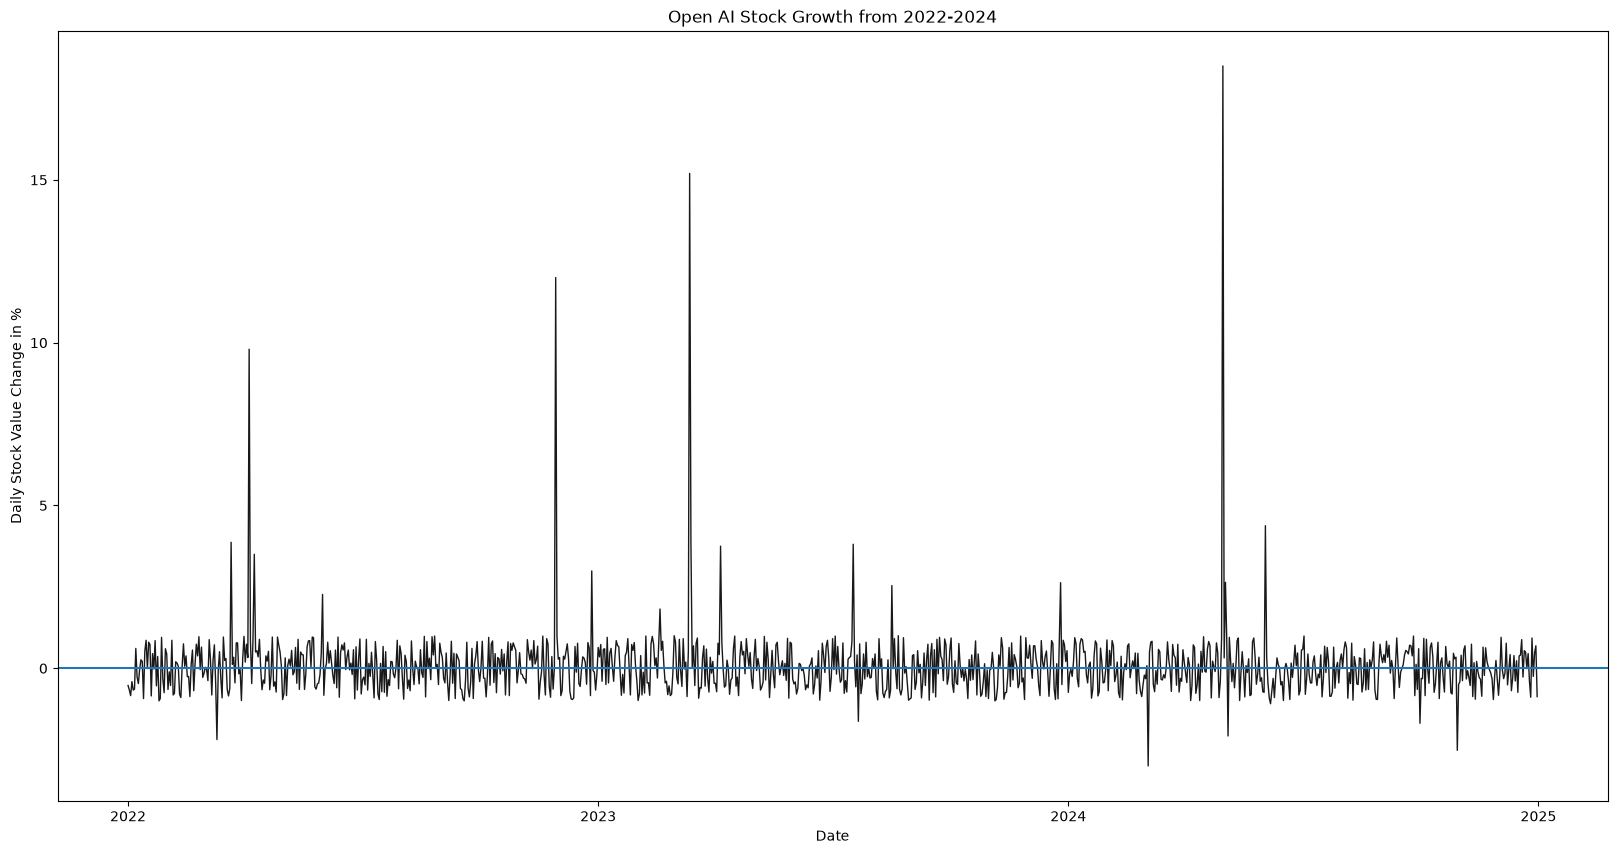

In [28]:
open_ai = finance[finance['Company'] == 'OpenAI']
open_ai_shortened = open_ai.tail(365*3)

plt.figure(figsize=(20,10))

plt.plot(
    open_ai_shortened['Date'],
    open_ai_shortened['Stock_Impact_%'], 
    color = 'black', 
    linestyle = '-', 
    linewidth = 1,
    alpha = 0.9
)

plt.title("Open AI Stock Growth from 2022-2024")
plt.xticks(ticks = [0, 365,365*2, 365*3], labels = [2022, 2023, 2024, 2025])
plt.xlabel("Date")
plt.ylabel("Daily Stock Value Change in %")
plt.axhline(y = 0)
plt.show()

### Review + Adding Annotations

Note how we are graphing **daily** change in stock growth, not stock growth; each spike and fall we see does not mean that the stock price dropped, just that it rose a significant amount on a certain day. Let's look into these 4 spikes to see what exactly caused these increases, then annotate those events on our graph:

- April 6th, 2022: release of Dalle-2, ChatGPT image generation model
- November 30th, 2022: release of ChatGPT/GPT 3.5
- March 14th, 2023: release of GPT-4, large multimodal AI model
- May 1st, 2024: release of GPT5, flagship ChatGPT model

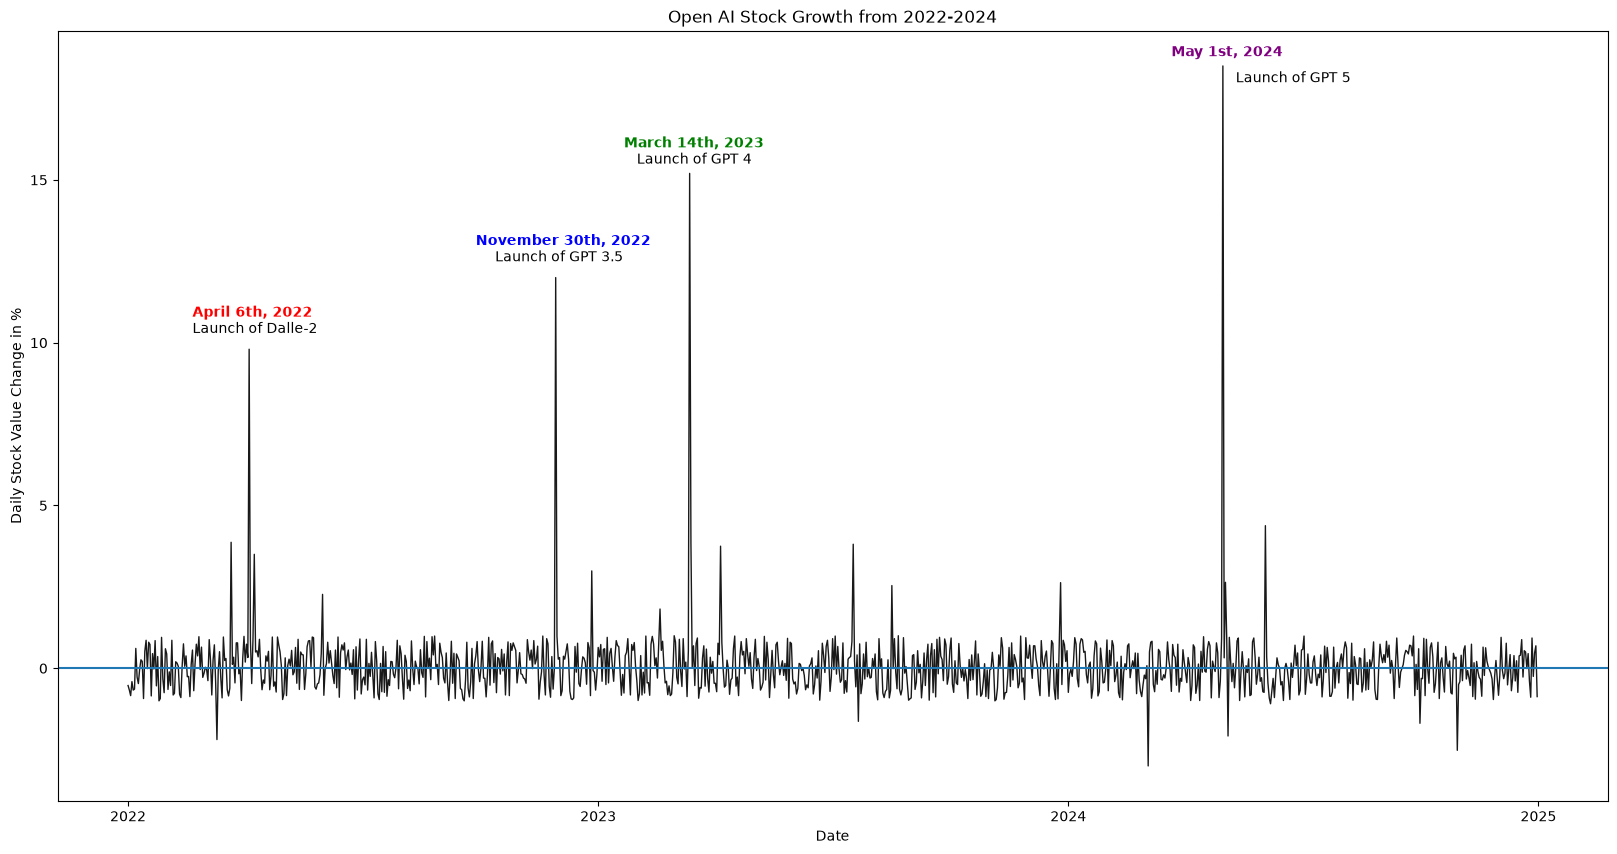

In [54]:
plt.figure(figsize=(20,10))

plt.plot(
    open_ai_shortened['Date'],
    open_ai_shortened['Stock_Impact_%'], 
    color = 'black', 
    linestyle = '-', 
    linewidth = 1,
    alpha = 0.9
)

plt.title("Open AI Stock Growth from 2022-2024")
plt.xticks(ticks = [0, 365,365*2, 365*3], labels = [2022, 2023, 2024, 2025])
plt.xlabel("Date")
plt.ylabel("Daily Stock Value Change in %")
plt.axhline(y = 0)
plt.text(50, 10.8, "April 6th, 2022", color = 'red', fontweight = 'bold')
plt.text(50, 10.3, "Launch of Dalle-2", color = 'black')
plt.text(270, 13, "November 30th, 2022", color = "blue", fontweight = 'bold')
plt.text(285, 12.5, "Launch of GPT 3.5", color = 'black')
plt.text(385, 16, "March 14th, 2023", color = "green", fontweight = 'bold')
plt.text(395, 15.5, "Launch of GPT 4", color = 'black')
plt.text(810, 18.8, "May 1st, 2024", color = "purple", fontweight = 'bold')
plt.text(860, 18, "Launch of GPT 5", color = 'black')

plt.show()


I really enjoy this example because we kind of discover this two-way feedback loop between our data and what it describes. By observing the graph of daily stock value changes, we can discover financially and   days in OpenAI company history (such as the releases of subsequent LLMs); similarly, we can identify these hallmark dates by looking at OpenAI's company history, then locate those datapoints more readily and observe exactly how large of an effect each of these dates had on OpenAI's value. Furthermore, it's incredibly easy to add simple annotations like lines and text, and these minor additions can really improve the legibility of a graph.

## Part 2: Directly Labeled Chart

Now, we'll make a directly labeled chart, or one that distinguishes groups using labels or colors, rather than a legend. For this, we'll now compare all 3 companies (OpenAI, Google, and Meta) and place their lines describing daily R&D (presumably research and development) spending. Instead of using a legend to distinguish the lines, we'll change their colors and also create a unique label for each line (also, let's look at just 2024):

### Creating the Chart

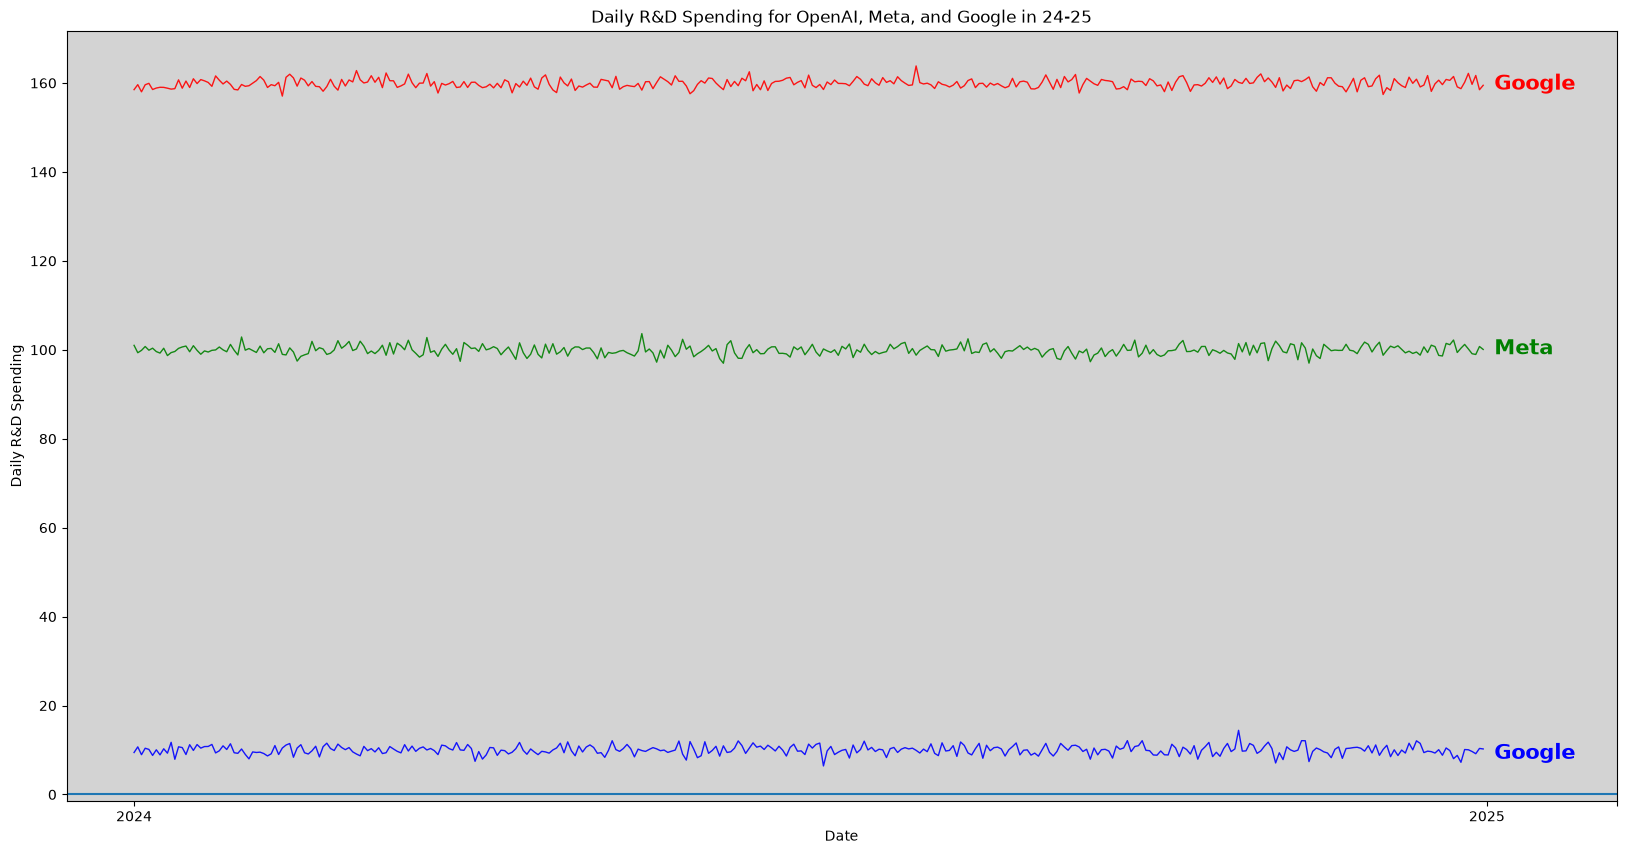

In [82]:
open_ai = finance[finance['Company'] == 'OpenAI']
open_ai_shortened_2 = open_ai.tail(365)

google = finance[finance['Company'] == 'Google']
google_shortened = google.tail(365)

meta = finance[finance['Company'] == 'Meta']
meta_shortened = meta.tail(365)

plt.figure(figsize = (20, 10))

plt.plot(
    open_ai_shortened_2['Date'],
    open_ai_shortened_2['R&D_Spending_USD_Mn'], 
    color = 'blue', 
    linestyle = '-', 
    linewidth = 1,
    alpha = 0.9
)

plt.plot(
    google_shortened['Date'],
    google_shortened['R&D_Spending_USD_Mn'], 
    color = 'red', 
    linestyle = '-', 
    linewidth = 1,
    alpha = 0.9
)

plt.plot(
    meta_shortened['Date'],
    meta_shortened['R&D_Spending_USD_Mn'], 
    color = 'green', 
    linestyle = '-', 
    linewidth = 1,
    alpha = 0.9
)

plt.title("Daily R&D Spending for OpenAI, Meta, and Google in 24-25")
plt.xticks(ticks = [0, 365, 400], labels = [2024, 2025, ""])
plt.xlabel("Date")
plt.ylabel("Daily R&D Spending")
plt.axhline(y = 0)
plt.text(367, 158.5, "Google", color = "red", fontweight = "bold", fontsize = 15)
plt.text(367, 99, "Meta", color = "green", fontweight = "bold", fontsize = 15)
plt.text(367, 8, "Google", color = "blue", fontweight = "bold", fontsize = 15)

plt.gca().set_facecolor('#D3D3D3')
plt.show()

While we would hope to see a little more parity and overlap in our line chart (each company spends basically the same amount every day aside from slight deviations), there is a sizable benefit to directly labeling our different lines as opposed to using a legend. Firstly, when having only a few groups (say 3-5), a legend isn't entirely necessary, and it can even be more powerful to label the lines directly. Furthermore, if we have a chart where different groups are very overtly distinguished, directly labeling those lines with their group makes the reader's job far easier; making them read a legend would just create an unnecessary hassle.

## Part 3: Formatted Table to Complement Visualization

Let's create a simple formatted table to complement our visualization. Here, we'll just get the means for R&D spending for each group, so we can know exactly what values we're looking at. We'll first make the table:

In [86]:
aggregated_finance = finance.groupby('Company')['R&D_Spending_USD_Mn'].agg('mean')
print(aggregated_finance)

Company
Google    115.888623
Meta       72.415294
OpenAI      7.249595
Name: R&D_Spending_USD_Mn, dtype: float64


### Formatting the Table; Improving Aesthetics

While we could leave this table as it, it's not particularly aesthetically pleasing or formatted, so let's remake it in a more fitting way:

In [90]:
table_data = [
    ["Google", 115.888625],
    ["Meta", 72.415294],
    ["OpenAI", 7.249595]
]

print(f"{'Company':<12} | {'Daily R&D Spending ($ in Mil)':<15}") 
print("-" * 45)
for row in table_data:
    print(f"{row[0]:<12} | {row[1]:<15}")

Company      | Daily R&D Spending ($ in Mil)
---------------------------------------------
Google       | 115.888625     
Meta         | 72.415294      
OpenAI       | 7.249595       


Now, we have a nicely formatted table to serve alongside our graph.

## Conclusion/Reflection

This was an excellent exercise in working with some of the minor/more underappreciated aspects of graphmaking and visualizations, being decisions on labeling and formatting. One lesson I've learned from all assignments of this class thus far (specifically this one as well) is that majorly effective design choices are usually just a few lines of simple code away; making small annotations on outlier revenue days for a company, creating baselines to contain data, and remaking a table to make it more legible were all simplistic, quick changes that had vast improvement on the comprehensibility and visual appeal of a graph. Overall, I look forward to combining all of these techniques and creating a powerful midterm project!